In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('breast_cancer_prediction.csv')

In [3]:
df.head()

,Patient_ID,Age,Gender,BMI,Family_History,Smoking,Alcohol_Consumption,Physical_Activity,Hormone_Therapy,Menopause_Status,...,Mammogram_Result,Biopsy_Result,Cancer_Stage,Cancer,Blood_Pressure,Cholesterol,Diabetes,Exercise_Days_Per_Week,Breastfeeding_History,Annual_Income_USD
0,100001,71,Female,27.2,Yes,Yes,Yes,High,No,Post,...,Suspicious,Malignant,Stage II,1,141,167,No,7,No,101316
1,100002,34,Male,26.0,No,No,No,High,No,Post,...,Normal,Benign,No Cancer,0,104,229,Yes,7,Yes,30023
2,100003,80,Female,20.7,No,No,No,High,No,Pre,...,Suspicious,Benign,No Cancer,0,161,275,No,1,Yes,34819
3,100004,40,Female,26.8,Yes,Yes,No,Moderate,No,Post,...,Normal,Benign,No Cancer,0,150,180,No,7,Yes,68025
4,100005,43,Female,28.6,Yes,Yes,No,Moderate,No,Post,...,Normal,Benign,No Cancer,0,110,266,No,0,Yes,90919


In [4]:
df.isnull().mean()*100

Patient_ID                0.0
Age                       0.0
Gender                    0.0
BMI                       3.0
Family_History            0.0
Smoking                   0.0
Alcohol_Consumption       3.0
Physical_Activity         3.0
Hormone_Therapy           3.0
Menopause_Status          0.0
Genetic_Mutation          0.0
Tumor_Size_cm             3.0
Lymph_Node_Involvement    0.0
Mammogram_Result          0.0
Biopsy_Result             0.0
Cancer_Stage              0.0
Cancer                    0.0
Blood_Pressure            0.0
Cholesterol               0.0
Diabetes                  0.0
Exercise_Days_Per_Week    0.0
Breastfeeding_History     0.0
Annual_Income_USD         0.0
dtype: float64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Patient_ID              10000 non-null  int64  
 1   Age                     10000 non-null  int64  
 2   Gender                  10000 non-null  object 
 3   BMI                     9700 non-null   float64
 4   Family_History          10000 non-null  object 
 5   Smoking                 10000 non-null  object 
 6   Alcohol_Consumption     9700 non-null   object 
 7   Physical_Activity       9700 non-null   object 
 8   Hormone_Therapy         9700 non-null   object 
 9   Menopause_Status        10000 non-null  object 
 10  Genetic_Mutation        10000 non-null  object 
 11  Tumor_Size_cm           9700 non-null   float64
 12  Lymph_Node_Involvement  10000 non-null  object 
 13  Mammogram_Result        10000 non-null  object 
 14  Biopsy_Result           10000 non-null 

In [7]:
df.shape

(10000, 23)

In [8]:
cols =  [var for var in df.columns if df[var].isnull().mean() <0.05 and df[var].isnull().mean() >0]

In [9]:
cols

['BMI',
 'Alcohol_Consumption',
 'Physical_Activity',
 'Hormone_Therapy',
 'Tumor_Size_cm']

In [10]:
df.dropna(subset=['BMI','Alcohol_Consumption','Physical_Activity','Hormone_Therapy','Tumor_Size_cm'], inplace= True)

In [11]:
df.isnull().mean()*100

Patient_ID                0.0
Age                       0.0
Gender                    0.0
BMI                       0.0
Family_History            0.0
Smoking                   0.0
Alcohol_Consumption       0.0
Physical_Activity         0.0
Hormone_Therapy           0.0
Menopause_Status          0.0
Genetic_Mutation          0.0
Tumor_Size_cm             0.0
Lymph_Node_Involvement    0.0
Mammogram_Result          0.0
Biopsy_Result             0.0
Cancer_Stage              0.0
Cancer                    0.0
Blood_Pressure            0.0
Cholesterol               0.0
Diabetes                  0.0
Exercise_Days_Per_Week    0.0
Breastfeeding_History     0.0
Annual_Income_USD         0.0
dtype: float64

In [12]:
# drop unwanted col
df.drop(columns= ['Patient_ID','Biopsy_Result','Cancer_Stage','Lymph_Node_Involvement'], inplace=True)

In [13]:
df.head()

,Age,Gender,BMI,Family_History,Smoking,Alcohol_Consumption,Physical_Activity,Hormone_Therapy,Menopause_Status,Genetic_Mutation,Tumor_Size_cm,Mammogram_Result,Cancer,Blood_Pressure,Cholesterol,Diabetes,Exercise_Days_Per_Week,Breastfeeding_History,Annual_Income_USD
0,71,Female,27.2,Yes,Yes,Yes,High,No,Post,Positive,2.46,Suspicious,1,141,167,No,7,No,101316
1,34,Male,26.0,No,No,No,High,No,Post,Negative,2.57,Normal,0,104,229,Yes,7,Yes,30023
2,80,Female,20.7,No,No,No,High,No,Pre,Negative,2.12,Suspicious,0,161,275,No,1,Yes,34819
3,40,Female,26.8,Yes,Yes,No,Moderate,No,Post,Negative,0.46,Normal,0,150,180,No,7,Yes,68025
4,43,Female,28.6,Yes,Yes,No,Moderate,No,Post,Negative,3.20,Normal,0,110,266,No,0,Yes,90919


In [14]:
# Encoding
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9700 entries, 0 to 9999
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Age                     9700 non-null   int64  
 1   Gender                  9700 non-null   object 
 2   BMI                     9700 non-null   float64
 3   Family_History          9700 non-null   object 
 4   Smoking                 9700 non-null   object 
 5   Alcohol_Consumption     9700 non-null   object 
 6   Physical_Activity       9700 non-null   object 
 7   Hormone_Therapy         9700 non-null   object 
 8   Menopause_Status        9700 non-null   object 
 9   Genetic_Mutation        9700 non-null   object 
 10  Tumor_Size_cm           9700 non-null   float64
 11  Mammogram_Result        9700 non-null   object 
 12  Cancer                  9700 non-null   int64  
 13  Blood_Pressure          9700 non-null   int64  
 14  Cholesterol             9700 non-null   int64

In [15]:
df['Family_History'] = df['Family_History'].map({'No': 0, 'Yes': 1})
df['Smoking'] = df['Smoking'].map({'No': 0, 'Yes': 1})
df['Hormone_Therapy'] = df['Hormone_Therapy'].map({'No': 0, 'Yes': 1})
df['Diabetes'] = df['Diabetes'].map({'No': 0, 'Yes': 1})
df['Breastfeeding_History'] = df['Breastfeeding_History'].map({'No': 0, 'Yes': 1, 'Not Applicable': np.nan})
df['Gender'] = df['Gender'].map({'Female': 0, 'Male': 1})
df['Alcohol_Consumption'] = df['Alcohol_Consumption'].map({'No': 0, 'Yes': 1})
df['Menopause_Status'] = df['Menopause_Status'].map({'Pre': 0, 'Post': 1})
df['Genetic_Mutation'] = df['Genetic_Mutation'].map({'Negative': 0, 'Positive': 1})

In [16]:
df = pd.get_dummies(df, columns=['Physical_Activity','Mammogram_Result'], drop_first=True, dtype=int)

In [17]:
df.sample(15)

,Age,Gender,BMI,Family_History,Smoking,Alcohol_Consumption,Hormone_Therapy,Menopause_Status,Genetic_Mutation,Tumor_Size_cm,...,Blood_Pressure,Cholesterol,Diabetes,Exercise_Days_Per_Week,Breastfeeding_History,Annual_Income_USD,Physical_Activity_Low,Physical_Activity_Moderate,Mammogram_Result_Normal,Mammogram_Result_Suspicious
371,52,0,23.9,1,0,0,1,1,0,2.92,...,114,154,0,0,1.0,54983,0,1,1,0
4132,48,0,29.6,0,1,0,0,0,0,2.27,...,139,210,0,0,1.0,53002,0,0,0,1
5185,60,0,18.3,0,1,0,0,1,0,2.88,...,171,249,0,6,1.0,56635,0,0,1,0
8382,77,0,30.1,1,0,0,0,1,0,4.34,...,127,260,0,0,1.0,106837,0,0,1,0
4256,77,0,33.5,0,0,1,0,0,0,0.52,...,161,172,1,3,1.0,146093,0,1,1,0
6980,44,0,32.1,1,0,1,0,0,0,2.47,...,173,196,0,1,NaN,93457,0,1,0,1
495,66,0,30.7,0,0,1,1,1,1,7.42,...,156,190,0,7,1.0,26028,1,0,0,0
5763,32,0,32.3,1,1,0,0,1,0,2.60,...,139,160,0,3,0.0,26224,0,0,1,0
9498,61,0,28.6,0,0,1,0,0,0,4.18,...,128,143,0,3,1.0,43592,0,0,1,0
98,22,0,24.7,0,0,1,0,1,1,1.66,...,104,202,0,4,1.0,102181,0,0,0,0


In [18]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy = 'median')

# Fit and transform (SimpleImputer expects a 2D array/DataFrame
df['Breastfeeding_History'] = imputer.fit_transform(df[['Breastfeeding_History']])

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9700 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Age                          9700 non-null   int64  
 1   Gender                       9700 non-null   int64  
 2   BMI                          9700 non-null   float64
 3   Family_History               9700 non-null   int64  
 4   Smoking                      9700 non-null   int64  
 5   Alcohol_Consumption          9700 non-null   int64  
 6   Hormone_Therapy              9700 non-null   int64  
 7   Menopause_Status             9700 non-null   int64  
 8   Genetic_Mutation             9700 non-null   int64  
 9   Tumor_Size_cm                9700 non-null   float64
 10  Cancer                       9700 non-null   int64  
 11  Blood_Pressure               9700 non-null   int64  
 12  Cholesterol                  9700 non-null   int64  
 13  Diabetes               

In [20]:
X = df.drop(columns=['Cancer'])
y = df['Cancer']

In [21]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split (X,y, test_size=0.2, random_state=42)

In [22]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

In [23]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Logistic Regression

In [24]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression()

In [25]:
lr.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [26]:
y_pred_lr = lr.predict(X_test_scaled)

In [27]:
print("Train Score:", lr.score(X_train_scaled, y_train))
print("Test Score :", lr.score(X_test_scaled, y_test))

Train Score: 0.9070876288659794
Test Score : 0.906701030927835


In [28]:
# check if any target column is in X..
print('Cancer' in X.columns)

False


In [29]:
from sklearn.metrics import recall_score,precision_score,f1_score

In [30]:
y_pred_lr = lr.predict(X_test_scaled)

In [31]:
print("f1 score_", f1_score (y_test,y_pred_lr))

f1 score_ 0.7489597780859917


In [32]:
print("Recall_", recall_score (y_test,y_pred_lr))

Recall_ 0.72


In [33]:
print("precision_", precision_score (y_test,y_pred_lr))

precision_ 0.7803468208092486


In [34]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.93      0.95      0.94      1565
           1       0.78      0.72      0.75       375

    accuracy                           0.91      1940
   macro avg       0.86      0.84      0.85      1940
weighted avg       0.90      0.91      0.91      1940



In [35]:
import matplotlib.pyplot as plt

accurcay = accuracy_score(y_test, y_pred_lr)

Bad value in file WindowsPath('C:/Users/MrAhs/anaconda3/Lib/site-packages/matplotlib/mpl-data/stylelib/classic.mplstyle'), line 162 ('mathtext.default: normal  # The default font to use for math.'): Key mathtext.default: 'normal' is not a valid value for mathtext.default; supported values are ['rm', 'cal', 'bfit', 'it', 'tt', 'sf', 'bf', 'default', 'bb', 'frak', 'scr', 'regular']

Bad key axes3d.depthshade in file C:\Users\MrAhs\anaconda3\Lib\site-packages\matplotlib\mpl-data\stylelib\classic.mplstyle, line 225 ('axes3d.depthshade   : False   # depth shade for 3D scatter plots')
You probably need to get an updated matplotlibrc file from
https://github.com/matplotlib/matplotlib/blob/v3.10.0/lib/matplotlib/mpl-data/matplotlibrc
or from the matplotlib source distribution

Bad key axes3d.depthshade_minalpha in file C:\Users\MrAhs\anaconda3\Lib\site-packages\matplotlib\mpl-data\stylelib\classic.mplstyle, line 226 ('axes3d.depthshade_minalpha : 0.3  # minimum alpha value for depth shading')


# KNN

In [36]:
from sklearn.neighbors import KNeighborsClassifier
Knn = KNeighborsClassifier()
Knn.fit(X_train,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [37]:
from sklearn.metrics import accuracy_score
y_pred_knn = Knn.predict(X_test)
accuracy_score(y_test,y_pred_knn)

0.772680412371134

In [38]:
from sklearn.metrics import classification_report, confusion_matrix
print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

           0       0.81      0.94      0.87      1565
           1       0.20      0.06      0.09       375

    accuracy                           0.77      1940
   macro avg       0.50      0.50      0.48      1940
weighted avg       0.69      0.77      0.72      1940



# SVM

In [39]:
from sklearn.svm import SVC

In [40]:
model = SVC(kernel= 'rbf', C=1.0, gamma='scale', random_state=42)

In [41]:
model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [42]:
y_pred_svm = model.predict(X_test_scaled)

In [43]:
acc = accuracy_score(y_test, y_pred_svm)
print("SVM Accuracy:", acc)

SVM Accuracy: 0.9097938144329897


In [44]:
from sklearn.metrics import classification_report, confusion_matrix
print(classification_report(y_test, y_pred_svm))

              precision    recall  f1-score   support

           0       0.93      0.96      0.95      1565
           1       0.82      0.68      0.75       375

    accuracy                           0.91      1940
   macro avg       0.87      0.82      0.85      1940
weighted avg       0.91      0.91      0.91      1940



#  DecisionTree

In [45]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42)

In [46]:
dt.fit(X_train_scaled, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

In [47]:
y_pred_dt = dt.predict(X_test_scaled)

In [48]:
acc_dt = accuracy_score(y_test, y_pred_dt)
print("Decision Tree Accuracy:", acc_dt)

Decision Tree Accuracy: 0.8680412371134021


In [49]:
from sklearn.metrics import classification_report, confusion_matrix
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.89      0.96      0.92      1565
           1       0.74      0.48      0.59       375

    accuracy                           0.87      1940
   macro avg       0.82      0.72      0.75      1940
weighted avg       0.86      0.87      0.86      1940



# RandomForest

In [50]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier()

In [51]:
rf.fit(X_train_scaled, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [52]:
y_pred_rf = rf.predict(X_test_scaled)

In [53]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.94      0.99      0.97      1565
           1       0.97      0.75      0.85       375

    accuracy                           0.95      1940
   macro avg       0.95      0.87      0.91      1940
weighted avg       0.95      0.95      0.94      1940



# RandomseacrhCV

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'class_weight': ['balanced']
}

search = RandomizedSearchCV(RandomForestClassifier(random_state=42), param_dist, n_iter=10, cv=3, random_state=42, n_jobs=-1, scoring='f1') 
search.fit(X_train_scaled, y_train)

print(search.best_params_)

In [ ]:
best_rf = search.best_estimator_
y_pred_tuned = best_rf.predict(X_test_scaled)

print(classification_report(y_test, y_pred_tuned))

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_tuned)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['No Cancer (0)', 'Cancer (1)'], 
            yticklabels=['No Cancer (0)', 'Cancer (1)'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Tuned Random Forest')
plt.show()

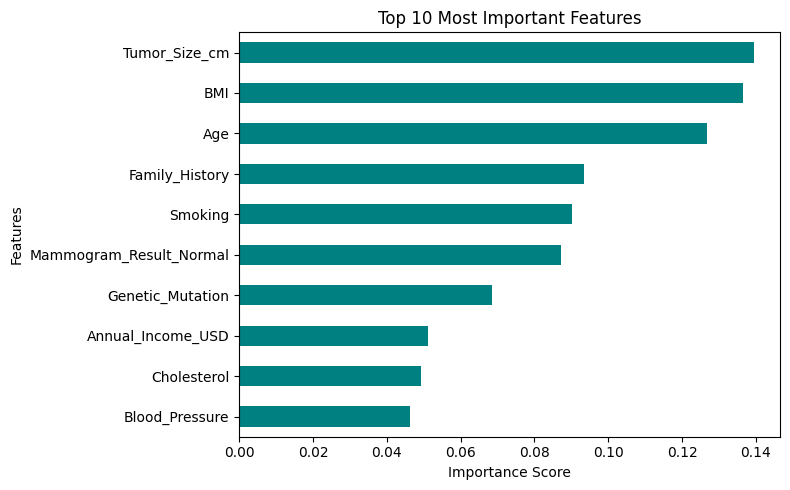

In [56]:
import pandas as pd
import matplotlib.pyplot as plt

# Feature importance 
importances = best_rf.feature_importances_
feature_names = X.columns

feat_importances = pd.Series(importances, index=feature_names)
feat_importances.nlargest(10).plot(kind='barh', figsize=(8, 5), color='teal')

plt.title('Top 10 Most Important Features')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [1]:
import pickle

model_data = {
    'model': best_rf,
    'scaler': scaler,
    'features': list(X.columns)
}

with open('breast cancer model.pkl', 'wb') as f:
    pickle.dump(model_data, f)

print("model.pkl successfully completed!")

NameError: name 'best_rf' is not defined